# Exercise 21 – Principal component analysis

**Week 4 · Descriptors and unsupervised learning**

PCA finds the directions along which data vary the most: the eigenvectors of
the covariance matrix, sorted by eigenvalue. Projecting onto the first two
gives the best 2D picture of high-dimensional data.

We implement PCA by hand, check it against scikit-learn, and use it to map
the 10-dimensional Coulomb-matrix spectra of all clusters onto a plane.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

from comphy import DATA_DIR
from comphy.atoms import LennardJones
from comphy.clusters import plot_cluster
from comphy.descriptors import CoulombMatrixSpectrum

rng = np.random.default_rng(0)
raw = np.loadtxt(DATA_DIR / "lj10clusters.txt")
positions = raw.reshape(len(raw), -1, 2)
calc = LennardJones()


class HomemadePCA:
    def __init__(self, n_components):
        self.n_components = n_components

    def fit(self, X):
        self.mean = X.mean(axis=0)
        eigenvalues, eigenvectors = np.linalg.eigh(np.cov((X - self.mean).T))
        order = np.argsort(eigenvalues)[::-1]
        self.explained_variance = eigenvalues[order][: self.n_components]
        self.components = eigenvectors[:, order][:, : self.n_components]
        return self

    def transform(self, X):
        return (X - self.mean) @ self.components

## A small example

same as scikit-learn (up to sign): True


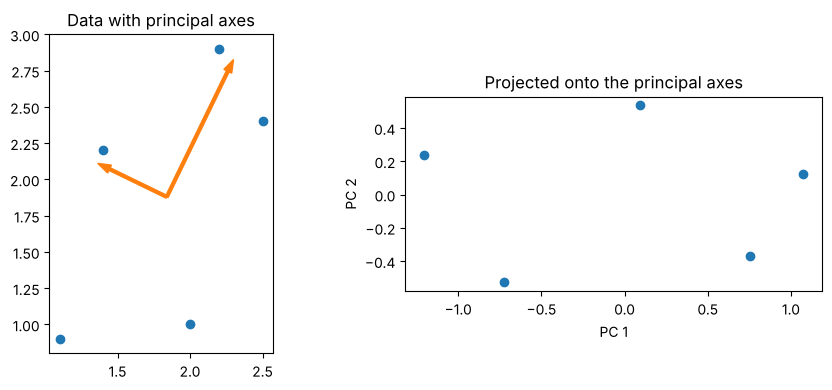

In [2]:
data = np.array([[2.5, 2.4], [2.0, 1.0], [2.2, 2.9], [1.4, 2.2], [1.1, 0.9]])
pca = HomemadePCA(2).fit(data)
projected = pca.transform(data)
sk = PCA(2).fit_transform(data)
print("same as scikit-learn (up to sign):", np.allclose(np.abs(projected), np.abs(sk)))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].scatter(*data.T)
for vec, var in zip(pca.components.T, pca.explained_variance):
    axes[0].arrow(*pca.mean, *(vec * np.sqrt(var)), width=0.02, color="C1")
axes[0].set(title="Data with principal axes", aspect="equal")
axes[1].scatter(*projected.T)
axes[1].set(title="Projected onto the principal axes", aspect="equal", xlabel="PC 1", ylabel="PC 2")
fig.tight_layout()
plt.show()

## PCA of atomic positions
Applied to the coordinates of a single cluster, PCA rotates it so that its
long axis lies along $x$.

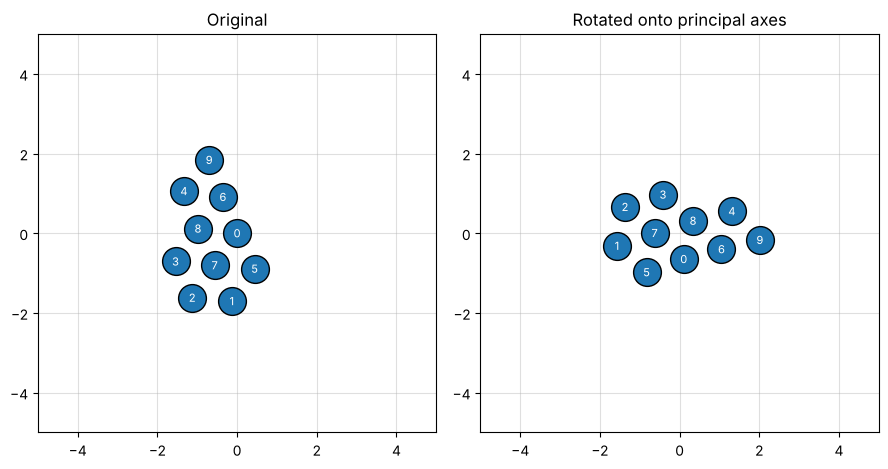

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
plot_cluster(axes[0], positions[10], size=400)
plot_cluster(axes[1], HomemadePCA(2).fit(positions[10]).transform(positions[10]), size=400)
for ax, title in zip(axes, ["Original", "Rotated onto principal axes"]):
    ax.set(xlim=(-5, 5), ylim=(-5, 5), title=title)
    ax.grid(True, alpha=0.4)
fig.tight_layout()
plt.show()

## A map of all clusters
Each cluster is described by its 10 Coulomb-matrix eigenvalues; PCA projects
these onto two dimensions.

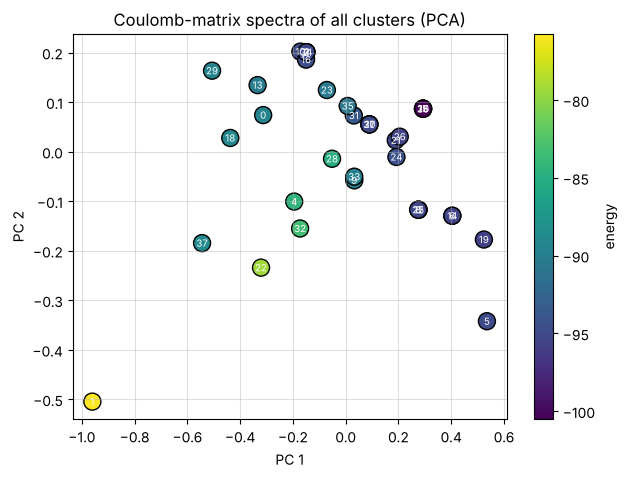

In [4]:
descriptor = CoulombMatrixSpectrum()
X = np.array([descriptor(p) for p in positions])
energies = np.array([calc.energy(p) for p in positions])
pca = HomemadePCA(2).fit(X)
Z = pca.transform(X)

fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(*Z.T, c=energies, cmap="viridis", s=150, edgecolor="black")
for i, (x, y) in enumerate(Z):
    ax.annotate(str(i), (x, y), fontsize=7, ha="center", va="center", color="white")
fig.colorbar(sc, ax=ax, label="energy")
ax.set(xlabel="PC 1", ylabel="PC 2", title="Coulomb-matrix spectra of all clusters (PCA)")
ax.grid(True, alpha=0.4)
plt.show()

## Is the map stable? Rattled clusters
Small random displacements ("rattling", 0.05 standard deviation) should give
nearby points in descriptor space. Below, nine rattled copies of four
clusters are projected onto the *same* principal axes as the dataset.

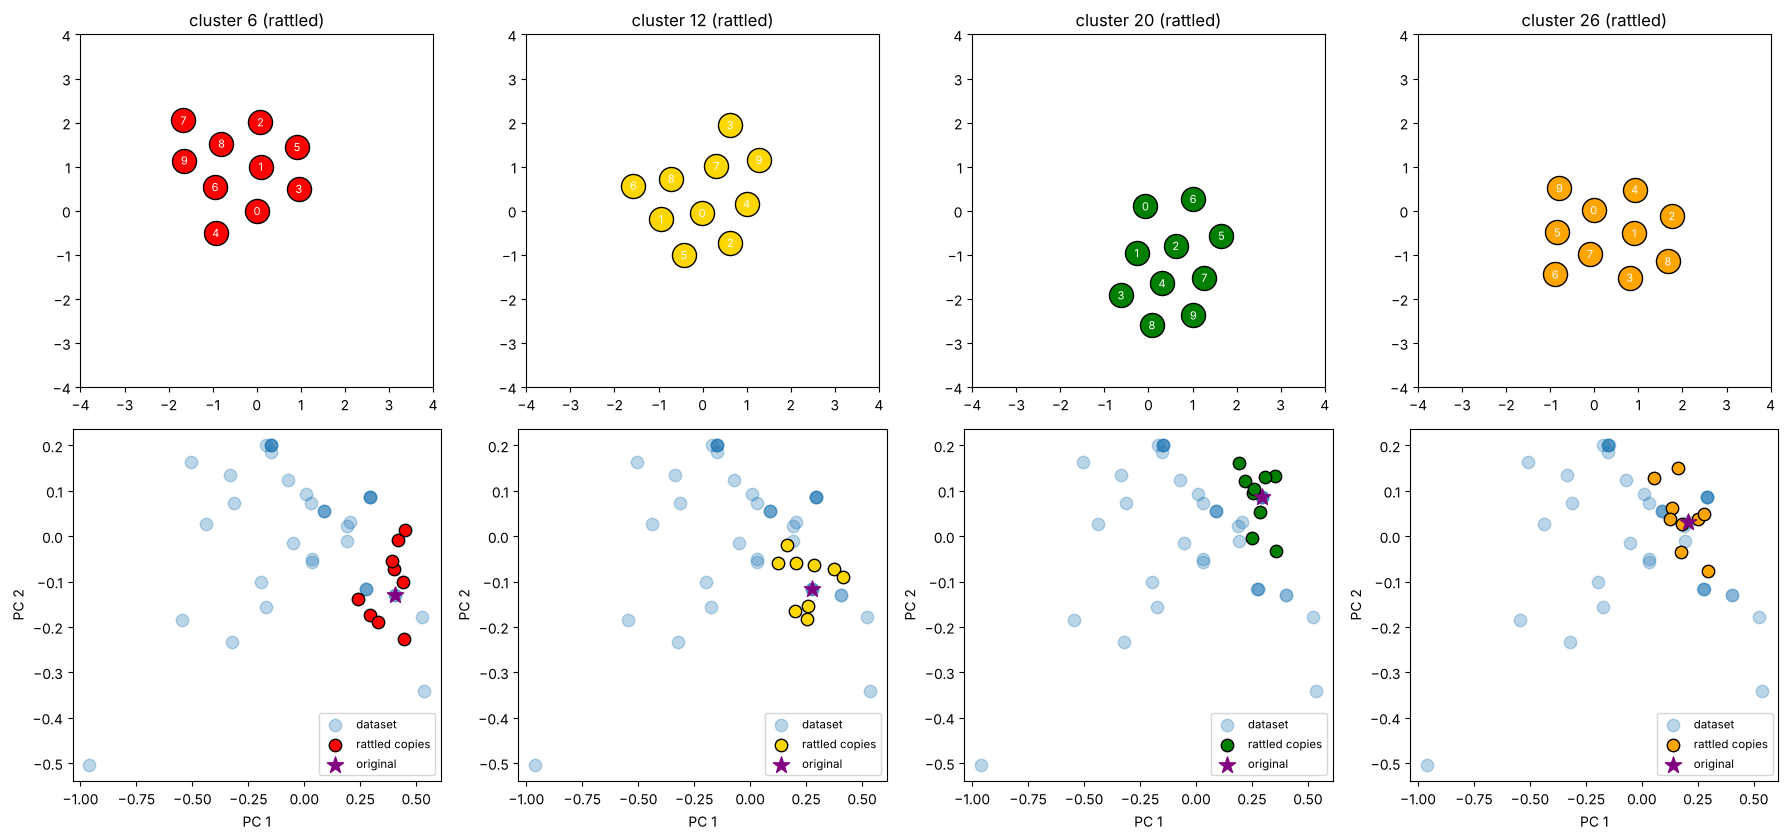

In [5]:
def rattled_copies(pos, n=9, amplitude=0.05):
    return [pos] + [pos + amplitude * rng.normal(size=pos.shape) for _ in range(n)]


chosen = [6, 12, 20, 26]
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
for col, (idx, color) in enumerate(zip(chosen, ["red", "gold", "green", "orange"])):
    copies = rattled_copies(positions[idx])
    plot_cluster(axes[0, col], copies[1], color=color, size=300)
    axes[0, col].set(xlim=(-4, 4), ylim=(-4, 4), title=f"cluster {idx} (rattled)")
    Zr = pca.transform(np.array([descriptor(p) for p in copies]))
    axes[1, col].scatter(*Z.T, s=80, color="C0", alpha=0.3, label="dataset")
    axes[1, col].scatter(*Zr[1:].T, s=80, color=color, edgecolor="black", label="rattled copies")
    axes[1, col].scatter(*Zr[0], s=150, color="purple", marker="*", label="original")
    axes[1, col].set(xlabel="PC 1", ylabel="PC 2")
    axes[1, col].legend(fontsize="small")
fig.tight_layout()
plt.show()

The rattled copies form a cloud around the original, but the cloud is about
as large as the distance between neighbouring structures in the map: the
Coulomb-matrix spectrum reacts quite strongly to displacements of only 0.05.
Similar structures can therefore not be told apart reliably in this
projection, while very different ones still end up in different regions.